# Week 3: Neural networks and deep learning

MNIST is the dataset used in the lecture. Section 2.1 is incomplete, and section 2.2 is missing the four- and five-layer results.

This notebook has been heavily revised and polished so I can use it as a reference in the future.

## Part 1: One neuron

### 1.1 Weighted sum and step activation
Weighted sum: `(x1 × w1) + (x2 × w2) + b`. The output is 1 if the sum is greater than zero; otherwise, it is 0.

- `(1, 0)`: `(1 × 0.6) + (0 × -0.4) - 0.3 = 0.3`, so the output is 1.
- `(0, 1)`: `(0 × 0.6) + (1 × -0.4) - 0.3 = -0.7`, so the output is 0.

### 1.2 What does a neuron do?
A neuron multiplies its inputs by weights, adds a bias, and applies an activation function to the result.

### 1.3 XOR attempts
XOR needs the outputs `0, 1, 1, 0` for inputs `(0,0), (0,1), (1,0), (1,1)`.

| w1 | w2 | bias | (0,0) | (0,1) | (1,0) | (1,1) |
|---:|---:|---:|---:|---:|---:|---:|
| 0.5 | 0.5 | -0.5 | 0 | 0 | 0 | 1 |
| 1 | -1 | -0.5 | 0 | 0 | 1 | 0 |
| 1 | 1 | -1.5 | 0 | 0 | 0 | 1 |
| -1 | -1 | 0.5 | 1 | 0 | 0 | 0 |

None of these combinations produces XOR. A single step neuron separates inputs with a straight line, but no straight line can separate the two positive XOR inputs from the two negative inputs.

## Part 2: TensorFlow Playground

### 2.1 Depth
With one hidden layer and eight neurons, the loss kept dropping, but pretty slowly. Adding a second layer brought test loss down to 0.325. Hidden layers with nonlinear activations can make more flexible boundaries.

This screenshot shows the circle dataset. I still need to try the spiral and find the smallest configuration that works.

![Circle experiment](images/Pasted%20image%2020261108201809.png)

### 2.2 Linear activation
The three-layer Tanh model had a test loss of 0.266. When I switched to Linear, the loss sank a little but got stuck around 0.496. It also stopped at 0.496 with six hidden layers, which confused me at first: why didn't all that extra room help it learn?

Stacking linear layers still produces a linear transformation, so adding more layers doesn't give the model a curved boundary. Playground shows loss rather than accuracy, and I didn't record results for four or five linear layers.

![Tanh configuration](images/Pasted%20image%2020261108202549.png)
![Six linear layers](images/Pasted%20image%2020261108202813.png)

### 2.3 Learning rate
At `0.00001`, the loss sank a little, but there wasn't much progress even after a long run. At `10`, the system radically overcorrected and the loss shot up. The first rate made updates too small; the second made them too large.

![Low learning rate](images/Pasted%20image%2020261108203030.png)
![High learning rate](images/Pasted%20image%2020261108203146.png)

### 2.4 Overfitting
With noise at 50, the model made progress quickly, then slowed down before the loss sank again and leveled off. The boundary has a blue center surrounded by orange, with some uneven edges. Training too long could make the model fit random noisy points instead of the general pattern.

![Noisy data](images/Pasted%20image%2020261108203415.png)

## Part 3: Keras experiments

Both models use the same layer sizes. The first uses ReLU and softmax activations; the second uses linear activations. The linear model outputs raw scores, so its loss uses `from_logits=True`.

In [1]:
from tensorflow import keras
import matplotlib.pyplot as plt

In [2]:
# Load the handwritten digit images used in the lecture.
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# Scale pixel values to between 0 and 1.
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [3]:
# Build the normal model: one hidden layer and ten output neurons.
keras.utils.set_random_seed(42)
normal_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
normal_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

### 3.1–3.2: Normal and linear models

Both models use the same data, validation split, epochs, batch size, and random seed. Accuracy is measured on the test set.

In [4]:
# Train the normal model and test it on images it hasn't seen.
normal_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2, verbose=2)
normal_loss, normal_accuracy = normal_model.evaluate(x_test, y_test, verbose=0)
print("Normal accuracy:", normal_accuracy)

Epoch 1/5


375/375 - 2s - 4ms/step - accuracy: 0.8935 - loss: 0.3876 - val_accuracy: 0.9427 - val_loss: 0.2084


Epoch 2/5


375/375 - 1s - 2ms/step - accuracy: 0.9495 - loss: 0.1804 - val_accuracy: 0.9556 - val_loss: 0.1544


Epoch 3/5


375/375 - 2s - 5ms/step - accuracy: 0.9628 - loss: 0.1306 - val_accuracy: 0.9625 - val_loss: 0.1283


Epoch 4/5


375/375 - 2s - 5ms/step - accuracy: 0.9712 - loss: 0.1020 - val_accuracy: 0.9663 - val_loss: 0.1128


Epoch 5/5


375/375 - 2s - 5ms/step - accuracy: 0.9774 - loss: 0.0825 - val_accuracy: 0.9688 - val_loss: 0.1036


Normal accuracy: 0.9713000059127808


In [5]:
# Use the same layer sizes, but set both activations to linear.
keras.utils.set_random_seed(42)
linear_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="linear"),
    keras.layers.Dense(10, activation="linear")
])
# Linear outputs are raw scores, so the loss needs from_logits=True.
linear_model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
linear_model.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.2, verbose=2)
linear_loss, linear_accuracy = linear_model.evaluate(x_test, y_test, verbose=0)
print("Normal accuracy:", normal_accuracy)
print("Linear accuracy:", linear_accuracy)

Epoch 1/5


375/375 - 3s - 7ms/step - accuracy: 0.8789 - loss: 0.4238 - val_accuracy: 0.9199 - val_loss: 0.2869


Epoch 2/5


375/375 - 2s - 4ms/step - accuracy: 0.9150 - loss: 0.3009 - val_accuracy: 0.9242 - val_loss: 0.2758


Epoch 3/5


375/375 - 2s - 5ms/step - accuracy: 0.9198 - loss: 0.2868 - val_accuracy: 0.9253 - val_loss: 0.2732


Epoch 4/5


375/375 - 2s - 5ms/step - accuracy: 0.9222 - loss: 0.2789 - val_accuracy: 0.9260 - val_loss: 0.2726


Epoch 5/5


375/375 - 2s - 5ms/step - accuracy: 0.9237 - loss: 0.2735 - val_accuracy: 0.9258 - val_loss: 0.2728


Normal accuracy: 0.9713000059127808
Linear accuracy: 0.9211000204086304


The normal model had a test accuracy of 0.9713. The linear model scored 0.9211.

### 3.3: Training and validation loss

The model trains for 30 epochs. The graph marks the epoch with the lowest validation loss.

In [6]:
# Train a fresh normal model for longer to look for overfitting.
keras.utils.set_random_seed(42)
overfit_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
overfit_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = overfit_model.fit(x_train, y_train, epochs=30, batch_size=128, validation_split=0.2, verbose=2)

Epoch 1/30


375/375 - 3s - 7ms/step - accuracy: 0.8935 - loss: 0.3876 - val_accuracy: 0.9427 - val_loss: 0.2084


Epoch 2/30


375/375 - 2s - 5ms/step - accuracy: 0.9495 - loss: 0.1804 - val_accuracy: 0.9556 - val_loss: 0.1544


Epoch 3/30


375/375 - 2s - 5ms/step - accuracy: 0.9628 - loss: 0.1306 - val_accuracy: 0.9625 - val_loss: 0.1283


... (50 outputs left out)

Epoch 29/30


375/375 - 2s - 5ms/step - accuracy: 1.0000 - loss: 8.7681e-04 - val_accuracy: 0.9762 - val_loss: 0.1158


Epoch 30/30


375/375 - 2s - 5ms/step - accuracy: 0.9956 - loss: 0.0134 - val_accuracy: 0.9735 - val_loss: 0.1329


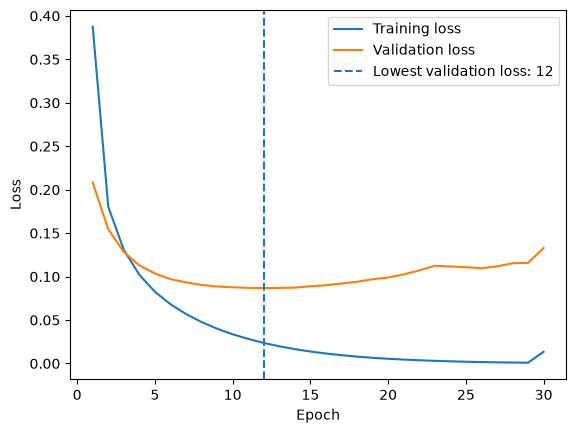

Lowest validation loss occurred at epoch 12


In [7]:
# Compare training loss with validation loss.
training_loss = history.history["loss"]
validation_loss = history.history["val_loss"]
best_epoch = validation_loss.index(min(validation_loss)) + 1

plt.plot(range(1, 31), training_loss, label="Training loss")
plt.plot(range(1, 31), validation_loss, label="Validation loss")
plt.axvline(best_epoch, linestyle="--", label=f"Lowest validation loss: {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
print("Lowest validation loss occurred at epoch", best_epoch)

Validation loss was lowest at epoch 12, then began to rise while training loss kept falling. Stopping near epoch 12 would limit further fitting to the training data.

## Part 4: Explanation

### 4.1 Backpropagation
The network makes a prediction, and the loss measures how far it is from the correct answer. Backpropagation traces that error backward through the network to determine how the weights contributed. The optimizer then adjusts the weights to reduce the error.

### 4.2 Personal reflection
Before this assignment, I didn't realize how flexible neural networks could be. I learned that backpropagation can adjust the network's weights to reduce a chosen loss, so the same basic training process can be applied to different problems by changing what the model is trained to measure.